Deep Neural Networks may help you tackle more complex problems, such as detecting hundreds of types of objects in a high-res image. There may be dozens or even hundreds of layers, each containing hundreds of neurons, linked by hundreds of thousands of connections. It is not a walk in a park and there are several problems you might run into:
- You may be faced with the problem of gradients growing ever smaller or larger when flowing backward thorugh the DNN during training. Both of these problems make lower layers very hard to train
- You might lack training data or it will be costly to label
- Training may be extremely slow
- Model with millions of parameters risks severely overfitting the training set, especially when lacking data or having too much noise

### The Vanishing/Exploding Gradients Problems

A deep neural network suffers from unstable gradients; different layers may learn at widely different speeds.

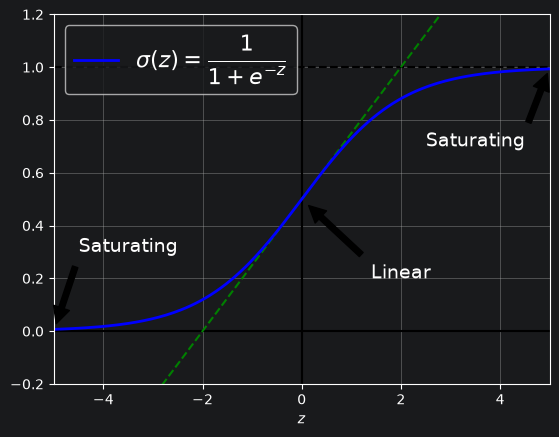

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import sys

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-5, 5, 200)

plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [1, 1], 'k--')
plt.plot([0, 0], [-0.2, 1.2], 'k-')
plt.plot([-5, 5], [-3/4, 7/4], 'g--')
plt.plot(z, sigmoid(z), "b-", linewidth=2,
         label=r"$\sigma(z) = \dfrac{1}{1+e^{-z}}$")
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Saturating', xytext=(3.5, 0.7), xy=(5, 1), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Saturating', xytext=(-3.5, 0.3), xy=(-5, 0), arrowprops=props,
             fontsize=14, ha="center")
plt.annotate('Linear', xytext=(2, 0.2), xy=(0, 0.5), arrowprops=props,
             fontsize=14, ha="center")
plt.grid(True)
plt.axis([-5, 5, -0.2, 1.2])
plt.xlabel("$z$")
plt.legend(loc="upper left", fontsize=16)

plt.show()

You can see when inputs become large, the function saturates at 0 or 1, with a derivative extremely close to 0. Thus, when backpropagation kicks in it has virtually no gradient to propagate back through the network, and what little gradient exists keeps getting diluted as backpropagation progresses down through the top layers, so there is really nothing left for the lower layers.

#### Glorot Initialization and He Initialization

For the signal to flow properly, we need the variance of the outputs of each layer to be equal to the variance of its inputs, and we need the gradients to have equal variance before and after flowing through a layer in the reverse direction.

We can guarantee both unless the layer has an equal number of inputs and outputs, but a good compromise is random initialization of connection weights at each layer.

Standart initialisation in nn.Linear isn't optimal. We can multiply the weights by 6^0.5 to get proper Kaiming initialization.

In [2]:
import torch
import torch.nn as nn

layer = nn.Linear(40, 10)
layer.weight.data *= 6 ** 0.05 # Kaiming int (or 3 ** 0.5 for LeCun init)
torch.zero_(layer.bias.data)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

This works. But there's a cleaner way.

In [3]:
nn.init.kaiming_uniform_(layer.weight)
nn.init.zeros_(layer.bias)

Parameter containing:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

To apply this to any linear layer, we can write a simple function

In [4]:
def use_he_init(module):
    if isinstance(module, nn.Linear):
        nn.init.kaiming_uniform_(module.weight)
        nn.init.zeros_(module.bias)

model = nn.Sequential(
    nn.Linear(50, 40),
    nn.ReLU(),
    nn.Linear(40, 1),
    nn.ReLU(),
)

model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): ReLU()
  (2): Linear(in_features=40, out_features=1, bias=True)
  (3): ReLU()
)

In a classifier, it is generally a good idea to scale down the weights of the output layer during initialization. Indeed, this will result in smaller logits at the beginning of training, which means they will be closer together, and hence the estimated probabilities will also be closer together. In other words, it encourages the model to be less confident about its predictions when training starts, thus avoiding extreme losses and huge gradients.

#### Better Activation Functions

ReLU was chosen as a better activation function, but it has a problem known as 'dying ReLU'. During training, some neurons effectively 'die', meaning, they stop outputting anything other than 0.

To solve this, we can use a variant called 'leaky ReLU'.

#### Leaky ReLU

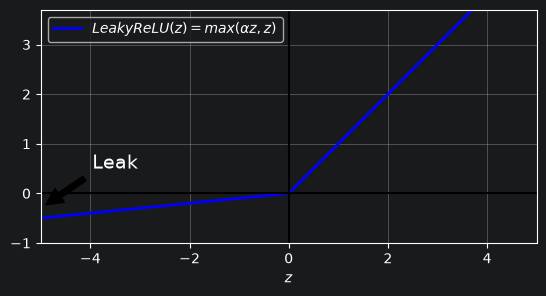

In [5]:
def leaky_relu(z, alpha):
    return np.maximum(alpha * z, z)

z = np.linspace(-5, 5, 200)
plt.plot(z, leaky_relu(z, 0.1), "b-", linewidth=2, label=r"$LeakyReLU(z) = max(\alpha z, z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-1, 3.7], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.3), arrowprops=props,
             fontsize=14, ha="center")
plt.xlabel("$z$")
plt.axis([-5, 5, -1, 3.7])
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

Having a slope for `z < 0` ensure that leaky ReLU never actually die; they can go into a long coma, but have a chance to eventually wake up.

In [6]:
alpha = 0.2
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=alpha))
nn.init.kaiming_uniform_(model[0].weight, alpha, nonlinearity="leaky_relu")

Parameter containing:
tensor([[-0.3198,  0.0820,  0.1380,  ..., -0.1878, -0.2153, -0.1375],
        [ 0.0127, -0.0511, -0.1811,  ...,  0.1303,  0.1327,  0.0670],
        [-0.2678, -0.1766,  0.0995,  ..., -0.2390,  0.3249, -0.2006],
        ...,
        [-0.1629,  0.1519, -0.2763,  ..., -0.0798, -0.1969, -0.2569],
        [-0.0201,  0.0552, -0.3017,  ...,  0.2972,  0.3179,  0.0293],
        [-0.3208,  0.1035,  0.3052,  ..., -0.0733, -0.2412,  0.1561]],
       requires_grad=True)

ReLU, leaky ReLU and PReLU all suffer from the fact that are not smooth functions: their slopes abruptly change at `z = 0`. Simillar to lasso, this sort of discontinuity in the derivatives can make gradient descent bounce around the optimum and slow down convergence.

#### ELU and SELU

Implementing ELU in PyTorch is trivial, just add an ELU layer after each Linear layer in your model, and make sure to use Kaiming initialization for these Linear layers:

In [7]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.ELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

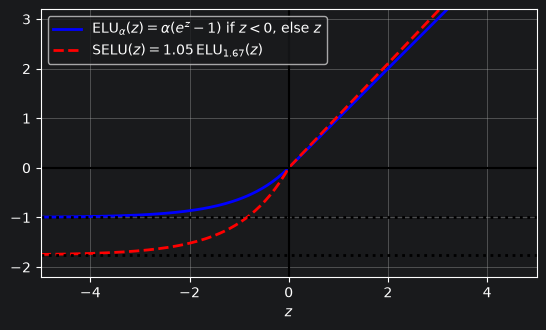

In [8]:
from scipy.special import erfc

# alpha and scale to self normalize with mean 0 and standard deviation 1
# (see equation 14 in the paper):
alpha_0_1 = -np.sqrt(2 / np.pi) / (erfc(1 / np.sqrt(2)) * np.exp(1 / 2) - 1)
scale_0_1 = (
    (1 - erfc(1 / np.sqrt(2)) * np.sqrt(np.e))
    * np.sqrt(2 * np.pi)
    * (
        2 * erfc(np.sqrt(2)) * np.e ** 2
        + np.pi * erfc(1 / np.sqrt(2)) ** 2 * np.e
        - 2 * (2 + np.pi) * erfc(1 / np.sqrt(2)) * np.sqrt(np.e)
        + np.pi
        + 2
    ) ** (-1 / 2)
)

def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

def selu(z, scale=scale_0_1, alpha=alpha_0_1):
    return scale * elu(z, alpha)

z = np.linspace(-5, 5, 200)
plt.plot(z, elu(z), "b-", linewidth=2, label=r"ELU$_\alpha(z) = \alpha (e^z - 1)$ if $z < 0$, else $z$")
plt.plot(z, selu(z), "r--", linewidth=2, label=r"SELU$(z) = 1.05 \, $ELU$_{1.67}(z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k:', linewidth=2)
plt.plot([-5, 5], [-1.758, -1.758], 'k:', linewidth=2)
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-5, 5, -2.2, 3.2])
plt.xlabel("$z$")
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [9]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.SELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

ELU and SELU ain't great. We got better options these days.

#### GELU, Swish, SwiGLU, Mish and RELU^2